In [8]:
import datamol as dm
# Function to turn smiles to mol
def smiles_to_mol(smiles):
    try:
        return dm.to_mol(smiles)
    except:
        raise ValueError("Please Enter a valid SMILES")    

In [9]:
mol_COO=smiles_to_mol("COO")

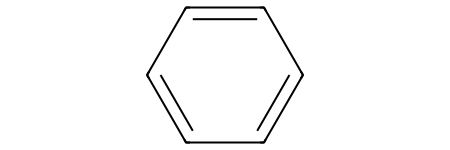

In [10]:
smiles_to_mol("c1ccccc1")

In [11]:
smiles_to_mol("not a smiles")

[10:47:47] SMILES Parse Error: syntax error while parsing: not
[10:47:47] SMILES Parse Error: check for mistakes around position 3:
[10:47:47] not
[10:47:47] ~~^
[10:47:47] SMILES Parse Error: Failed parsing SMILES 'not' for input: 'not'


In [12]:
print(smiles_to_mol("not_a_smiles"))    # None

None


[10:47:48] SMILES Parse Error: syntax error while parsing: not_a_smiles
[10:47:48] SMILES Parse Error: check for mistakes around position 3:
[10:47:48] not_a_smiles
[10:47:48] ~~^
[10:47:48] SMILES Parse Error: Failed parsing SMILES 'not_a_smiles' for input: 'not_a_smiles'


In [13]:
# The better Version
def smiles_to_mol(smiles):
    mol = dm.to_mol(smiles)
    if mol is None:
        raise ValueError("Please enter a valid SMILES string.")
    return mol

In [14]:
non_smiles = smiles_to_mol("not a smiles")

[10:47:48] SMILES Parse Error: syntax error while parsing: not
[10:47:48] SMILES Parse Error: check for mistakes around position 3:
[10:47:48] not
[10:47:48] ~~^
[10:47:48] SMILES Parse Error: Failed parsing SMILES 'not' for input: 'not'


ValueError: Please enter a valid SMILES string.

In [15]:
def mol_to_fingerprint(mol, fp_type='topological'):
    return dm.to_fp(mol, fp_type=fp_type)


In [16]:
mol_to_fingerprint(mol_COO)

array([0, 0, 0, ..., 0, 0, 0], shape=(2048,), dtype=uint8)

In [17]:
mol_to_fingerprint(non_smiles)

NameError: name 'non_smiles' is not defined

In [18]:
fp = mol_to_fingerprint(mol_COO)
print(fp.sum())

0


In [19]:
nol1=smiles_to_mol("c1ccccc1")

In [20]:
fp = mol_to_fingerprint(nol1)
print(fp.sum())

3


In [21]:
mol_ethanol = smiles_to_mol("CCO")
mol_methane = smiles_to_mol("C")

print(mol_to_fingerprint(mol_ethanol).sum())
print(mol_to_fingerprint(mol_methane).sum())

0
0


In [22]:
def too_few_bits(fingerprint, min_bits=1):
    """Check whether a fingerprint has too few set bits to be reliable.

    Very small molecules (for example ethanol or methane) get an empty
    topological fingerprint, so the model cannot tell them apart and its
    prediction is not trustworthy.

    Args:
        fingerprint: NumPy array of 0s and 1s (2048 bits).
        min_bits: Minimum number of set bits required. Default is 1,
            which only flags an empty fingerprint.

    Returns:
        True if the fingerprint has fewer than `min_bits` bits set,
        otherwise False.
    """
    n_bits = fingerprint.sum()
    return n_bits < min_bits


In [23]:
print(too_few_bits(mol_to_fingerprint(smiles_to_mol("CCO"))))        # expected True
print(too_few_bits(mol_to_fingerprint(smiles_to_mol("c1ccccc1"))))   # expected False
print(too_few_bits(mol_to_fingerprint(smiles_to_mol("c1ccccc1")), min_bits=5))   # expected True

True
False
True


In [24]:
import numpy as np

def build_input(fingerprint, temperature_K, scaler):
    """Build the one-row model input: fingerprint + scaled temperature.

    Args:
        fingerprint: array of 2048 values from `mol_to_fingerprint`.
        temperature_K: temperature in Kelvin.
        scaler: the fitted StandardScaler saved after training.

    Returns:
        Array of shape (1, 2049).
    """
    T_scaled = scaler.transform([[temperature_K]])            # shape (1, 1)
    X = np.hstack((fingerprint.reshape(1, -1), T_scaled))     # shape (1, 2049)
    return X

In [27]:
import joblib
scaler = joblib.load("../models/temperature_scaler.joblib")

fp = mol_to_fingerprint(smiles_to_mol("c1ccccc1"))
X = build_input(fp, 298.15, scaler)

print(X.shape)       # expect (1, 2049)
print(X[0, -1])      # the scaled temperature

(1, 2049)
-0.9075810683529043


In [28]:
print(scaler.mean_, scaler.scale_)
print((298.15 - scaler.mean_[0]) / scaler.scale_[0])    # should equal X[0, -1]

[423.12392246] [137.7000103]
-0.9075810683529043


In [34]:
# Function to predict pressure
import joblib
from xgboost import XGBRegressor
import numpy as np
model = XGBRegressor()
model.load_model("../models/models/xgb_tuned.json")

def predict_pressure(X, model):
    ln_p = model.predict(X)[0]
    return ln_p, float(np.exp(ln_p))

In [31]:
np.exp(np.log(12.7))

np.float64(12.700000000000001)

In [36]:
fp = mol_to_fingerprint(smiles_to_mol("c1ccccc1"))
X = build_input(fp, 298.15, scaler)
ln_p, p = predict_pressure(X, model)
print("ln_p: ", ln_p)
print("pressure,kPa: ", p)

ln_p:  2.5976796
pressure,kPa:  13.43253231048584


In [40]:
def predict_from_smiles(smiles, temperature_K, model, scaler, min_bits=1):
    """Predict the vapor pressure of a molecule at a given temperature.

    Args:
        smiles: SMILES string of the molecule.
        temperature_K: temperature in Kelvin.
        model: the fitted XGBoost model.
        scaler: the fitted temperature scaler.
        min_bits: minimum set bits for the fingerprint to be considered reliable.

    Returns:
        Dictionary with the pressure in kPa, ln P, the number of set
        fingerprint bits, and a flag that is True when the prediction
        should not be trusted (too few bits).

    Raises:
        ValueError: If the SMILES string is invalid.
    """
    mol = smiles_to_mol(smiles)
    fingerprint = mol_to_fingerprint(mol)
    X = build_input(fingerprint, temperature_K, scaler)
    ln_p, p = predict_pressure(X, model)
    return {
        "pressure_kPa": float(p),
        "ln_p": float(ln_p),
        "n_bits": int(fingerprint.sum()),
        "warn": bool(too_few_bits(fingerprint, min_bits)),
    }
    

In [41]:
predict_from_smiles('c1ccccc1', 298.15, model, scaler,min_bits=1)

{'pressure_kPa': 13.43253231048584,
 'ln_p': 2.597679615020752,
 'n_bits': 3,
 'warn': False}

In [42]:
predict_from_smiles('CCO', 298.15, model, scaler,min_bits=1)

{'pressure_kPa': 25.31882095336914,
 'ln_p': 3.2315480709075928,
 'n_bits': 0,
 'warn': True}